# Clasificación de gatos y perros mediante fine tuning de redes convolucionales preentrenadas

### Juan Sebastian Garcia Perez

**Problema:** dada la fotografía de una mascota, determinar automáticamente si es un gato o un perro.

**Dominio:** Visión artificial, clasificación de imágenes de animales domésticos.

**Utilidad:** Automatizar el etiquetado de fotos de mascotas. Un refugio o un portal de adopción recibe miles de fotos y necesita clasificarlas por especie sin que una persona las revise una por una.

**Base de datos:** Cats vs Dogs: 23.262 fotografías a color y 1 variable de salida categórica binaria. BD publicada en [TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs).

**Tipo de problema:** aprendizaje supervisado de clasificación binaria de imágenes.

**Modelos entrenados:** VGG16 y ResNet50 preentrenadas con ImageNet, ajustadas con fine tuning y búsqueda en malla de hiperparámetros.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.model_selection import ParameterGrid
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.19.0
GPU disponible: True


# 2. Descripción de la BD

Cats vs Dogs fue creada por Microsoft Research junto con Petfinder.com, un portal de adopción de mascotas de Estados Unidos. Las fotos son de animales reales de refugios y fueron etiquetadas a mano por el personal de esos refugios. Nació en 2007 para el proyecto Asirra, un CAPTCHA que pedía distinguir gatos de perros porque en ese momento era una tarea fácil para una persona y muy difícil para una máquina.

| Característica | Valor |
|---|---|
| Imágenes | 23.262 fotografías JPEG a color |
| Variable de entrada | image: matriz de píxeles de alto x ancho x 3 canales (RGB), enteros de 0 a 255 |
| Variable de salida | label (binaria) (cat / dog) |
| Tamaño de las imágenes | Variable, entre 4 y 500 píxeles de lado (mediana 467 x 375) |
| Imágenes dañadas | 1.738 de las 25.000 originales, ya eliminadas por TensorFlow Datasets |
| Reparto de clases | 11.658 gatos (50,1 %), 11.604 perros (49,9 %) |
| Particiones de origen | Solo trae train, la separación en entrenamiento, validación y prueba la hacemos nosotros |

Variable de salida (label):

| Aspecto | label |
|---|---|
| Qué es | La especie del animal de la foto |
| Tipo | Categórica nominal (sin orden) y binaria |
| Valores | cat (11.658 imágenes, 50,1 %) y dog (11.604 imágenes, 49,9 %) |
| Codificación | cat -> 0, dog -> 1 (ya viene codificada) |

A diferencia de una base de datos tabular, aquí no hay columnas con significado propio: las variables de entrada son los píxeles, y un píxel suelto no dice nada. Lo que distingue a un gato de un perro son patrones espaciales (orejas, hocico, pelaje), y por eso se usan redes neuronales convolucionales.

# 3. Carga de los datos

La BD se descarga directamente desde TensorFlow Datasets. Como solo trae la partición train, la dividimos en 70 % para entrenamiento, 15 % para validación (elegir hiperparámetros y modelo) y 15 % para prueba (evaluación final).

In [2]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True)

CLASES = ["gato", "perro"]

print("etiquetas originales:", info.features["label"].names)
print("imagenes totales:", info.splits["train"].num_examples)
print("entrenamiento:", len(ds_train), ", validacion:", len(ds_val), ", prueba:", len(ds_test))

etiquetas originales: ['cat', 'dog']
imagenes totales: 23262
entrenamiento: 16283 , validacion: 3490 , prueba: 3489


# 4. Análisis exploratorio de datos (EDA)

## 4.1 Estructura de una imagen

FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'image/filename': Text(shape=(), dtype=string),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
})

forma (alto, ancho, canales): (262, 350, 3) , tipo: uint8
valor minimo: 0 , valor maximo: 255
etiqueta: 1 -> perro


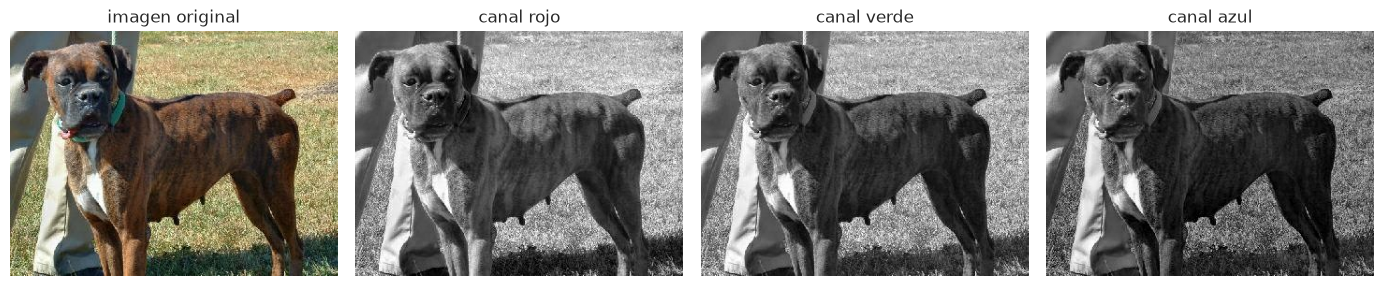

In [3]:
print(info.features)

imagen, etiqueta = next(iter(tfds.as_numpy(ds_train.take(1))))

print()
print("forma (alto, ancho, canales):", imagen.shape, ", tipo:", imagen.dtype)
print("valor minimo:", imagen.min(), ", valor maximo:", imagen.max())
print("etiqueta:", etiqueta, "->", CLASES[etiqueta])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(imagen)
axes[0].set_title("imagen original")
for i, canal in enumerate(["rojo", "verde", "azul"]):
    axes[i + 1].imshow(imagen[:, :, i], cmap="gray")
    axes[i + 1].set_title("canal " + canal)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Cada imagen es una matriz de NumPy de tres dimensiones (alto, ancho y 3 canales de color) con enteros de 0 a 255. En la descripción el alto y el ancho aparecen como None porque cambian de una foto a otra. Los tres canales se parecen mucho entre sí, lo que indica que la información útil está en las formas y texturas más que en el color.

## 4.2 Imágenes de cada clase

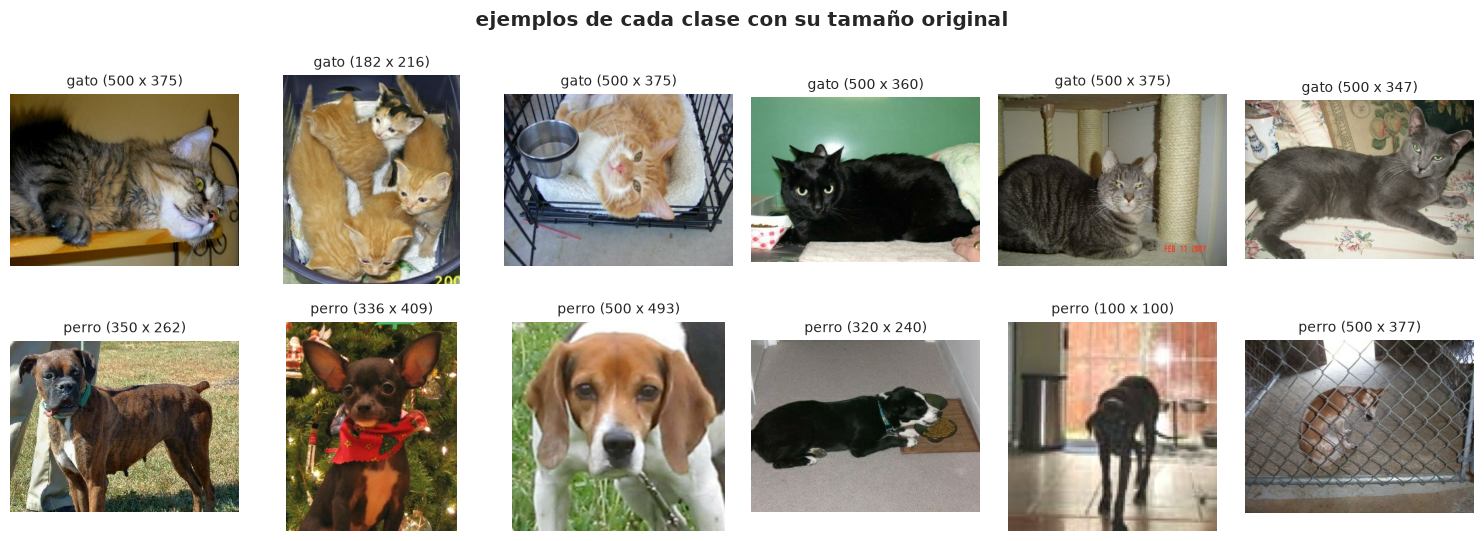

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))

for fila, clase in enumerate(CLASES):
    ejemplos = ds_train.filter(lambda img, y: y == fila).take(6)
    for ax, (img, y) in zip(axes[fila], tfds.as_numpy(ejemplos)):
        ax.imshow(img)
        ax.set_title(f"{clase} ({img.shape[1]} x {img.shape[0]})", fontsize=10)
        ax.axis("off")

plt.suptitle("ejemplos de cada clase con su tamaño original", fontweight="bold")
plt.tight_layout()
plt.show()

Son fotos caseras muy variadas: distintas razas, poses, fondos e iluminación, a veces con personas, jaulas u otros objetos, y cada una con su propio tamaño y proporción. No hay ningún rasgo simple, como un color o una posición, que separe las dos clases a simple vista.

## 4.3 Reparto de clases y tamaño de las imágenes

In [5]:
def medidas(ds, conjunto):
    filas = ds.map(lambda img, y: (tf.shape(img)[0], tf.shape(img)[1], y),
                   num_parallel_calls=tf.data.AUTOTUNE)
    tabla = pd.DataFrame(list(filas.as_numpy_iterator()), columns=["alto", "ancho", "clase"])
    return tabla.assign(conjunto=conjunto)

df = pd.concat([medidas(ds_train, "entrenamiento"), medidas(ds_val, "validacion"), medidas(ds_test, "prueba")],
               ignore_index=True)
df["clase"] = df["clase"].map(dict(enumerate(CLASES)))

display(pd.crosstab(df["conjunto"], df["clase"], margins=True, margins_name="total"))
print("imagenes con algun lado menor de 50 px:", ((df["alto"] < 50) | (df["ancho"] < 50)).sum())
df[["alto", "ancho"]].describe().round(1)

clase,gato,perro,total
conjunto,,,
entrenamiento,8195,8088,16283
prueba,1720,1769,3489
validacion,1743,1747,3490
total,11658,11604,23262


imagenes con algun lado menor de 50 px: 10


,alto,ancho
count,23262.0,23262.0
mean,364.9,410.2
std,96.2,108.0
min,4.0,4.0
25%,316.0,336.0
50%,375.0,467.0
75%,428.0,500.0
max,500.0,500.0


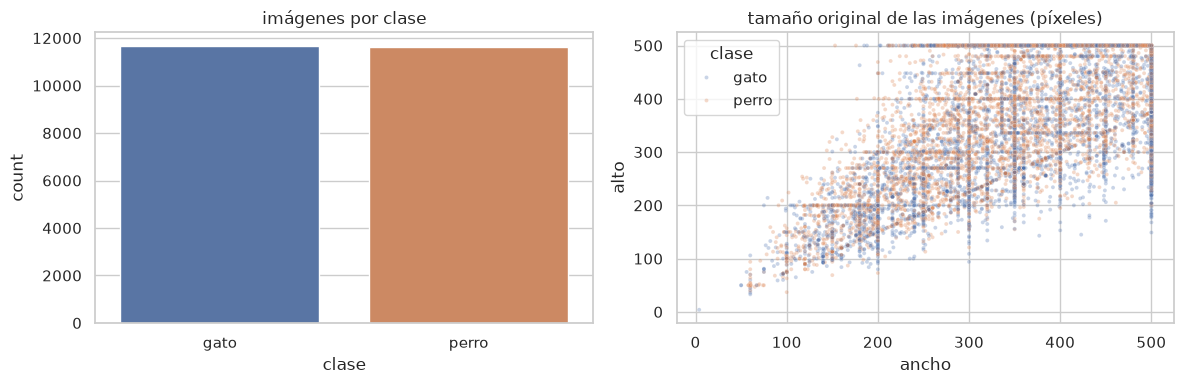

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="clase", hue="clase", order=CLASES, hue_order=CLASES, legend=False, ax=axes[0])
axes[0].set_title("imágenes por clase")

sns.scatterplot(data=df, x="ancho", y="alto", hue="clase", hue_order=CLASES, s=8, alpha=0.3, ax=axes[1])
axes[1].set_title("tamaño original de las imágenes (píxeles)")

plt.tight_layout()
plt.show()

Las clases están prácticamente equilibradas (50,1 % gatos y 49,9 % perros) y el reparto se mantiene en los tres conjuntos, así que la exactitud es una métrica justa y no hace falta balancear nada.

El tamaño sí varía mucho. Ninguna imagen supera los 500 píxeles de lado, la mayoría son apaisadas (mediana de 467 x 375) y hay 10 imágenes diminutas de menos de 50 píxeles que al ampliarlas quedan borrosas. Son tan pocas que se dejan.

## 4.4 Conclusiones del análisis exploratorio

| # | Hallazgo | Conclusión |
|---|---|---|
| 1 | 23.262 imágenes a color con una etiqueta binaria | Es un problema de clasificación binaria de imágenes |
| 2 | Clases repartidas 50,1 % vs 49,9 % en los tres conjuntos | No hace falta balancear y la exactitud es una métrica justa |
| 3 | Cada imagen tiene su propio tamaño (de 4 a 500 píxeles de lado) | Es obligatorio redimensionar todas a un tamaño fijo |
| 4 | Píxeles enteros de 0 a 255 en 3 canales | Hay que aplicar la normalización que espera cada red preentrenada |
| 5 | Mucha variedad de razas, poses, fondos y encuadres | Los píxeles sueltos no sirven, hace falta una red convolucional |
| 6 | Son fotos de perros y gatos, clases que ImageNet ya contiene | Un modelo preentrenado con ImageNet debería transferir muy bien |
| 7 | Hay imágenes diminutas, borrosas o con otros objetos | No se alcanzará el 100 % de exactitud |

# 5. Preparación de los datos

Gracias al EDA sabemos que solo hacen falta dos cosas:

1. **Redimensionar todas las imágenes a 160 x 160:** la red necesita que todas las entradas tengan la misma forma. Se redimensiona sin recortar, lo que deforma un poco la proporción pero conserva el animal completo. Se guardan como enteros de 0 a 255 y se dejan en memoria con cache() para no volver a decodificar los JPEG en cada época.

2. **Agrupar en lotes:** el tamaño del lote es uno de los hiperparámetros de la malla, por eso se aplica al final con una función. El conjunto de entrenamiento además se baraja en cada época.

La normalización de los píxeles no se hace aquí porque cada arquitectura tiene la suya (la misma con la que fue preentrenada) y va dentro del propio modelo.

Para que la malla sea rápida se usa una muestra de 5.000 imágenes de entrenamiento. Los modelos finales sí se entrenan con las 16.283.

In [7]:
IMG = 160

def redimensionar(img, y):
    return tf.cast(tf.image.resize(img, (IMG, IMG)), tf.uint8), y

def preparar(ds):
    return ds.map(redimensionar, num_parallel_calls=tf.data.AUTOTUNE).cache()

def lotes(ds, batch, barajar=False):
    if barajar:
        ds = ds.shuffle(2000, seed=RANDOM_STATE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train, val, test = preparar(ds_train), preparar(ds_val), preparar(ds_test)
muestra = preparar(ds_train.take(5000))

print(lotes(train, 32).element_spec)

(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


# 6. Modelos preentrenados y fine tuning

Se prueban dos arquitecturas preentrenadas con ImageNet (1,2 millones de imágenes de 1.000 clases, entre ellas más de 100 razas de perros y varias de gatos):

- **VGG16:** 13 capas convolucionales apiladas una tras otra en 5 bloques.
- **ResNet50:** 50 capas con conexiones residuales (atajos que suman la entrada de un bloque a su salida), lo que permite entrenar redes mucho más profundas.

De cada una se toma solo la base convolucional (include_top=False) y se le añade una cabeza nueva: GlobalAveragePooling -> Dense(unidades, relu) -> Dropout(0,3) -> Dense(1, sigmoid).

El entrenamiento se hace en dos fases:

1. **Solo la cabeza:** la base está congelada y actúa como extractor de características. Si se entrenara todo desde el inicio, los gradientes grandes de una cabeza recién inicializada dañarían los pesos preentrenados.

2. **Fine tuning:** se descongela el último bloque convolucional (block5 en VGG16, conv5 en ResNet50) y se sigue entrenando con una tasa de aprendizaje muy baja (1e-5) para adaptar esas características a nuestro problema sin perder lo aprendido.

Las dos fases usan el optimizador Adam y la pérdida binary_crossentropy, la habitual con una salida sigmoide. La base se llama con training=False para que las capas BatchNormalization de ResNet50 sigan usando las estadísticas de ImageNet, y se compila con jit_compile=False porque al crear muchos modelos seguidos la compilación XLA de cada uno gasta más tiempo y memoria de la que ahorra.

In [8]:
apps = tf.keras.applications
ARQUITECTURAS = {
    "VGG16":    (apps.VGG16,    apps.vgg16.preprocess_input,    "block5"),
    "ResNet50": (apps.ResNet50, apps.resnet50.preprocess_input, "conv5"),
}
LR_FINE_TUNING = 1e-5

def compilar(modelo, lr):
    modelo.compile(tf.keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"], jit_compile=False)

def crear_modelo(arq, unidades, lr):
    constructor, preprocesar, _ = ARQUITECTURAS[arq]
    tf.keras.utils.set_random_seed(RANDOM_STATE)

    base = constructor(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = False

    entrada = tf.keras.Input((IMG, IMG, 3))
    x = preprocesar(entrada)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(unidades, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    salida = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    modelo = tf.keras.Model(entrada, salida)
    compilar(modelo, lr)
    return modelo, base

def descongelar(modelo, base, arq):
    base.trainable = True
    for capa in base.layers:
        capa.trainable = capa.name.startswith(ARQUITECTURAS[arq][2])
    compilar(modelo, LR_FINE_TUNING)

def entrenar(arq, unidades, lr, batch, datos, epocas, verbose=0):
    tr, va = lotes(datos, batch, barajar=True), lotes(val, batch)
    modelo, base = crear_modelo(arq, unidades, lr)
    h1 = modelo.fit(tr, validation_data=va, epochs=epocas, verbose=verbose)      # fase 1: solo la cabeza
    descongelar(modelo, base, arq)
    h2 = modelo.fit(tr, validation_data=va, epochs=epocas, verbose=verbose)      # fase 2: fine tuning
    return modelo, {k: h1.history[k] + h2.history[k] for k in h1.history}

In [9]:
def entrenables(modelo):
    return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))

filas = []
for arq in ARQUITECTURAS:
    modelo, base = crear_modelo(arq, 64, 1e-3)
    fase1 = entrenables(modelo)
    descongelar(modelo, base, arq)
    filas.append({"arquitectura": arq, "capas de la base": len(base.layers),
                  "parametros totales": modelo.count_params(),
                  "entrenables fase 1": fase1, "entrenables fase 2": entrenables(modelo)})

pd.DataFrame(filas).set_index("arquitectura")

,capas de la base,parametros totales,entrenables fase 1,entrenables fase 2
arquitectura,,,,
VGG16,19,14747585,32897,7112321
ResNet50,175,23718913,131201,15107201


En la fase 1 solo se entrena la cabeza, menos del 1 % de los parámetros (unos 33 mil en VGG16 y 131 mil en ResNet50 con 64 unidades). En el fine tuning se suma el último bloque convolucional: 7,1 millones en VGG16 (48 %) y 15,1 millones en ResNet50 (64 %). Las capas anteriores siguen congeladas porque detectan rasgos genéricos (bordes, colores, texturas) que sirven para cualquier imagen.